# Industrial surface defect segmentation

Predict four defect masks per image.

In [1]:
%pip install -q "segmentation-models-pytorch>=0.5,<0.7" optuna wandb seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 3.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
import torch.nn.functional as F
import wandb
from kaggle_secrets import UserSecretsClient
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, WeightedRandomSampler

DATA = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TRAIN_DIR, TEST_DIR = DATA / "train", DATA / "test"
WORK = Path("/kaggle/working")
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
H, W = 128, 800
WANDB_PROJECT = "surface-defect-final-run3"
SEED, BATCH = 42, 32
cv2.setNumThreads(1)
wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: amitoj (24f2002444) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Images and masks

The CSV gives one-based runs down the columns. Each image has four independent masks.

In [3]:
def rle_decode(rle, shape=(H, W)):
    mask = np.zeros(np.prod(shape), np.uint8)
    numbers = list(map(int, rle.split()))
    for start, length in zip(numbers[::2], numbers[1::2]):
        mask[start - 1:start - 1 + length] = 1
    return mask.reshape(shape, order="F")  # Column-major


def rle_encode(mask):
    pixels = np.pad(mask.ravel(order="F"), 1)
    # Run boundaries
    runs = np.flatnonzero(pixels[1:] != pixels[:-1]) + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))


def read_image(folder, image_id):
    image = cv2.imread(str(folder / f"{image_id}.jpg"), cv2.IMREAD_GRAYSCALE)
    return image.astype(np.float32) / 255


train_df = pd.read_csv(DATA / "train.csv", dtype={"image_id": str}, keep_default_na=False)
sample = pd.read_csv(DATA / "sample_submission.csv", dtype={"image_id": str}, keep_default_na=False)
labels = (train_df.pivot(index="image_id", columns="defect_type", values="mask_rle")
          .sort_index()[CLASSES].fillna(""))
ids, rles = labels.index.to_numpy(), labels.to_numpy()
areas = labels.map(lambda r: sum(map(int, r.split()[1::2])))
present = (areas > 0).astype(int)
print(f"{len(ids):,} train images · {sample.image_id.nunique():,} test images")

11,393 train images · 3,000 test images


## Exploratory data analysis

<Axes: title={'center': 'Images per defect class'}, xlabel='defect_type'>

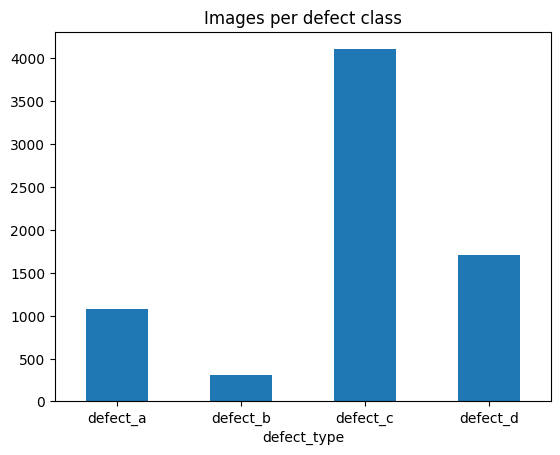

In [4]:
present.sum().plot.bar(title="Images per defect class", rot=0)

<Axes: title={'center': 'Defect classes per image'}>

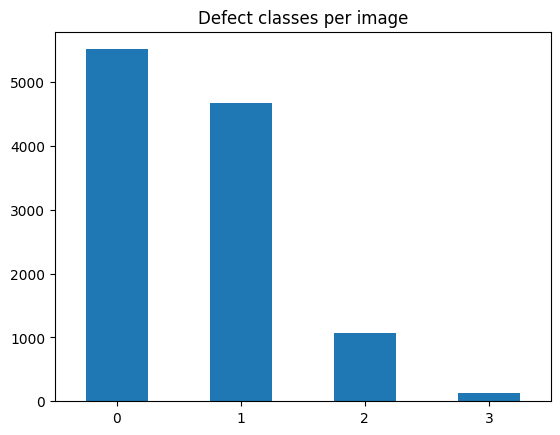

In [5]:
present.sum(axis=1).value_counts().sort_index().plot.bar(title="Defect classes per image", rot=0)

<Axes: title={'center': 'Positive mask area (pixels)'}>

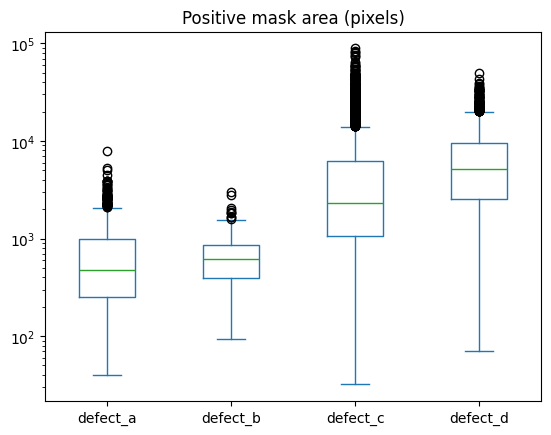

In [6]:
areas[areas > 0].plot.box(title="Positive mask area (pixels)", logy=True)

Text(0.5, 1.0, 'Class co-occurrence')

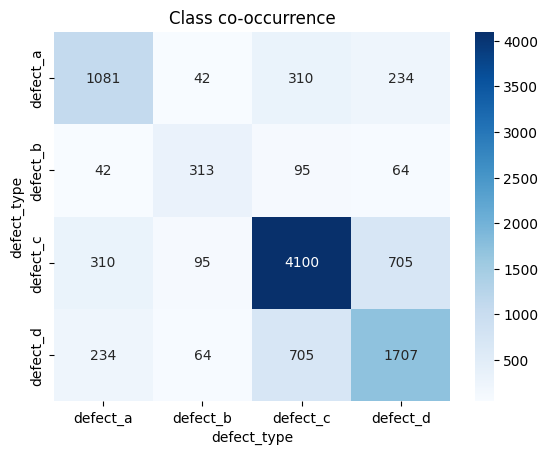

In [7]:
sns.heatmap(present.T @ present, annot=True, fmt="d", cmap="Blues").set_title("Class co-occurrence")

Text(0.5, 1.0, 'Defect B outline · 025UEJ2TKX')

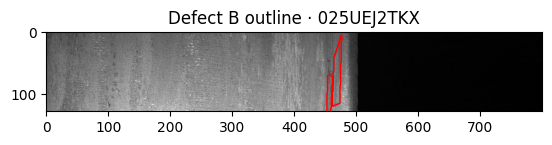

In [8]:
image_id = present["defect_b"].idxmax()
plt.imshow(read_image(TRAIN_DIR, image_id), cmap="gray")
plt.contour(rle_decode(labels.at[image_id, "defect_b"]), levels=[0.5], colors="red", linewidths=1)
plt.title(f"Defect B outline · {image_id}")

## Split and preprocessing

Stratify by defect combination. Training uses rare-defect oversampling, flips, brightness and contrast changes, and small shifts, rotations and scale changes.

In [9]:
patterns = present.astype(str).agg("".join, axis=1)
# Rare combinations
strata = patterns.where(patterns.map(patterns.value_counts()) >= 3, "rare")
train_idx, val_idx = train_test_split(
    np.arange(len(ids)), test_size=0.15, random_state=SEED,
    stratify=strata)
frequency = present.iloc[train_idx].mean().clip(lower=0.001)
rarity = present.div(np.sqrt(frequency)).max(axis=1).to_numpy()


def training_batch(indices):
    images, masks = [], []
    for i in indices:
        image = read_image(TRAIN_DIR, ids[i])
        mask = np.stack([rle_decode(r) for r in rles[i]], axis=-1)
        # Paired flips
        for axis in (0, 1):
            if random.random() < 0.5:
                image, mask = np.flip(image, axis), np.flip(mask, axis)
        if random.random() < 0.5:
            image = np.clip(image * random.uniform(0.85, 1.15) + random.uniform(-0.05, 0.05), 0, 1)
        if random.random() < 0.5:
            matrix = cv2.getRotationMatrix2D(((W-1)/2, (H-1)/2), random.uniform(-3, 3), random.uniform(0.9, 1.1))
            matrix[:, 2] += [W * random.uniform(-0.04, 0.04), H * random.uniform(-0.05, 0.05)]
            image = cv2.warpAffine(image, matrix, (W, H), borderMode=cv2.BORDER_REFLECT)
            mask = cv2.warpAffine(mask, matrix, (W, H), flags=cv2.INTER_NEAREST)
        images.append(image)
        masks.append(mask.transpose(2, 0, 1))
    return torch.from_numpy(np.stack(images)), torch.from_numpy(np.stack(masks))


# Validation cache
val_images = torch.from_numpy(np.stack([read_image(TRAIN_DIR, ids[i]) for i in val_idx]))
truth = np.stack([[rle_decode(r) for r in rles[i]] for i in val_idx])
loader_settings = dict(batch_size=BATCH, num_workers=2, prefetch_factor=1, persistent_workers=True)
val_loader = DataLoader(list(zip(val_images, truth)), **loader_settings)

## Three models

The scratch U-Net saves four encoder features and reuses them in reverse order during upsampling. All three models predict four pixel masks and four image-level presence scores.

In [10]:
def double_conv(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.down = nn.ModuleList([double_conv(3, 24), double_conv(24, 48),
                                   double_conv(48, 96), double_conv(96, 192)])
        self.middle = double_conv(192, 384)
        self.up, self.decode = nn.ModuleList(), nn.ModuleList()
        for width in (192, 96, 48, 24):
            self.up.append(nn.ConvTranspose2d(2 * width, width, 2, stride=2))
            self.decode.append(double_conv(2 * width, width))
        self.mask = nn.Conv2d(24, 4, 1)
        self.presence = nn.Sequential(nn.Dropout(0.2), nn.Linear(384, 4))

    def forward(self, x):
        skips = []
        for block in self.down:
            skip = block(x)
            skips.append(skip)
            x = F.max_pool2d(skip, 2)
        x = self.middle(x)
        presence = self.presence(x.mean((2, 3)))
        # Skip connections
        for up, block, skip in zip(self.up, self.decode, reversed(skips)):
            x = block(torch.cat([up(x), skip], dim=1))
        return self.mask(x), presence


V1, V2 = "tu-convnext_tiny", "tu-convnextv2_tiny"


def make_model(name, weights="imagenet"):
    if name == "scratch":
        return SmallUNet()
    return smp.Unet(encoder_name=name, encoder_weights=weights, classes=4,
                    decoder_attention_type="scse", aux_params={"classes": 4, "dropout": 0.2})

## Training and validation

The loss combines pixel BCE, Dice and presence BCE. The validation score averages the four classes. Each class gets 70% foreground Dice, 20% correct empty predictions on empty targets and 10% empty/nonempty accuracy.

In [11]:
def total_loss(seg, cls, target, hp):
    dims = (0, 2, 3)
    # Rare defects
    weights = seg.new_tensor([1.9, 1.9, 1, 1])
    pixel_bce = F.binary_cross_entropy_with_logits(seg, target, reduction="none").mean(dims)
    p = seg.sigmoid()
    dice_loss = 1 - (2 * (p * target).sum(dims) + 1) / (p.sum(dims) + target.sum(dims) + 1)
    present = target.amax((2, 3))
    presence_bce = F.binary_cross_entropy_with_logits(cls, present, reduction="none").mean(0)
    losses = pixel_bce + hp["dice_w"] * dice_loss + hp["cls_w"] * presence_bce
    return (weights * losses).sum() / weights.sum()


def class_score(inter, pred_area, true_area):
    empty = true_area == 0
    dice = 2 * inter / np.maximum(pred_area + true_area, 1)
    foreground = dice[~empty].mean()
    correct_empty = (pred_area[empty] == 0).mean()
    accuracy = ((pred_area == 0) == empty).mean()
    return 0.7 * foreground + 0.2 * correct_empty + 0.1 * accuracy


def logits(model, gray):
    x = (gray.cuda() - 0.449) / 0.226
    x = x[:, None].expand(-1, 3, -1, -1).contiguous(memory_format=torch.channels_last)
    with torch.autocast("cuda"):
        seg, cls = model(x)
    return seg.float(), cls.float()


@torch.inference_mode()
def validate(model):
    counts = []
    for gray, target in val_loader:
        seg, cls = logits(model, gray)
        # Presence gate
        pred = (seg.sigmoid() > 0.2) & (cls.sigmoid() > 0.05)[:, :, None, None]
        target = target.cuda().bool()
        counts.append(torch.stack([(pred & target).sum((2, 3)), pred.sum((2, 3)), target.sum((2, 3))]).cpu())
    inter, pred_area, true_area = torch.cat(counts, dim=1).float().numpy()
    return np.mean([class_score(inter[:, c], pred_area[:, c], true_area[:, c]) for c in range(4)])

In [12]:
def fit(name, hp, indices, epochs, trial=None):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = make_model(name).to("cuda", memory_format=torch.channels_last)
    # Oversampling
    sampler = WeightedRandomSampler(1 + 1.7 * rarity[indices], len(indices), replacement=True)
    loader = DataLoader(indices, sampler=sampler, collate_fn=training_batch, drop_last=True, **loader_settings)
    decoder = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    groups = [{"params": decoder, "lr": hp["lr"]}]
    if name != "scratch":
        groups.append({"params": model.encoder.parameters(), "lr": 0.29 * hp["lr"]})
    optimizer = torch.optim.AdamW(groups, weight_decay=0.01)
    schedule = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, [g["lr"] for g in groups], epochs=epochs, steps_per_epoch=len(loader), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda")
    ema = copy.deepcopy(model).eval().requires_grad_(False)
    best, best_epoch, step = -1, 0, 0

    for epoch in range(1, epochs + 1):
        train_losses = []
        for gray, target in loader:
            optimizer.zero_grad(set_to_none=True)
            seg, cls = logits(model, gray)
            loss = total_loss(seg, cls, target.cuda().float(), hp)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            schedule.step()
            train_losses.append(loss.item())

            # Weight averaging
            step += 1
            decay = min(0.99, (1 + step) / (10 + step))
            current = model.state_dict()
            for key, value in ema.state_dict().items():
                if value.is_floating_point():
                    value.lerp_(current[key], 1 - decay)
                else:
                    value.copy_(current[key])

        score = validate(ema)
        print(f"{name} · epoch {epoch}/{epochs} · validation {score:.4f}")
        if trial is None:
            wandb.log(dict(train_loss=np.mean(train_losses), val_score=score), step=epoch)
        else:
            trial.report(score, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if score > best:
            best, best_epoch = score, epoch
            if trial is None and name != "scratch":
                torch.save(ema.state_dict(), WORK / f"{name}.pth")
    return best_epoch, best

## Optuna and W&B

Tune the learning rate and two loss weights on a quarter of the training split. Use the full validation split for every trial, then train each model on the full training split.

In [13]:
tune_idx = np.random.default_rng(SEED).permutation(train_idx)[:len(train_idx) // 4]


def objective(trial):
    hp = dict(lr=trial.suggest_float("lr", 3e-4, 1.2e-3, log=True),
              dice_w=trial.suggest_float("dice_w", 0.5, 1.5), cls_w=trial.suggest_float("cls_w", 0.1, 0.6))
    _, score = fit(V1, hp, tune_idx, 3, trial)
    return score


study = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1))
# Starting values
study.enqueue_trial(dict(lr=0.00076, dice_w=0.78, cls_w=0.26))
study.optimize(objective, n_trials=6, gc_after_trial=True)
print("Best hyperparameters", study.best_params)

model_results = []
for name, label, epochs in [("scratch", "Scratch U-Net", 6), (V2, "ConvNeXt V2-Tiny U-Net", 10),
                            (V1, "ConvNeXt-Tiny U-Net", 18)]:
    hp = study.best_params.copy()
    if name == "scratch":
        hp["lr"] = 0.001
    with wandb.init(project=WANDB_PROJECT, name=name, config={**hp, "epochs": epochs}) as run:
        best_epoch, score = fit(name, hp, train_idx, epochs)
        run.summary.update({"best_epoch": best_epoch, "best_val_score": score})
        model_results.append((label, epochs, best_epoch, score))

[I 2026-11-27 07:25:39,258] A new study created in memory with name: no-name-ca5b5d8f-6e34-44b4-8ecc-440c5593a670
/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_23/2017856290.py:29: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  schedule.step()


tu-convnext_tiny · epoch 1/3 · validation 0.1840
tu-convnext_tiny · epoch 2/3 · validation 0.4082


[I 2026-11-27 07:29:21,207] Trial 0 finished with value: 0.4803062219733849 and parameters: {'lr': 0.00076, 'dice_w': 0.78, 'cls_w': 0.26}. Best is trial 0 with value: 0.4803062219733849.


... (23 outputs left out)

tu-convnext_tiny · epoch 1/18 · validation 0.2467
tu-convnext_tiny · epoch 2/18 · validation 0.5203
tu-convnext_tiny · epoch 3/18 · validation 0.5176
tu-convnext_tiny · epoch 4/18 · validation 0.5742
tu-convnext_tiny · epoch 5/18 · validation 0.5930
tu-convnext_tiny · epoch 6/18 · validation 0.6071
tu-convnext_tiny · epoch 7/18 · validation 0.6183
tu-convnext_tiny · epoch 8/18 · validation 0.6192
tu-convnext_tiny · epoch 9/18 · validation 0.6332
tu-convnext_tiny · epoch 10/18 · validation 0.6358
tu-convnext_tiny · epoch 11/18 · validation 0.6375
tu-convnext_tiny · epoch 12/18 · validation 0.6401
tu-convnext_tiny · epoch 13/18 · validation 0.6474
tu-convnext_tiny · epoch 14/18 · validation 0.6492
tu-convnext_tiny · epoch 15/18 · validation 0.6522
tu-convnext_tiny · epoch 16/18 · validation 0.6573
tu-convnext_tiny · epoch 17/18 · validation 0.6543


wandb: updating run metadata


tu-convnext_tiny · epoch 18/18 · validation 0.6543


wandb: uploading wandb-summary.json; uploading config.yaml; uploading output.log
wandb: 
wandb: Run history:
wandb: train_loss █▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁
wandb:  val_score ▁▆▆▇▇▇▇▇██████████
wandb: 
wandb: Run summary:
wandb:     best_epoch 16
wandb: best_val_score 0.65729
wandb:     train_loss 0.28756
wandb:      val_score 0.65426
wandb: 
wandb: 🚀 View run tu-convnext_tiny at: https://wandb.ai/24f2002444/surface-defect-final-run3/runs/htmevvf8
wandb: ⭐️ View project at: https://wandb.ai/24f2002444/surface-defect-final-run3
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261127_085039-htmevvf8/logs


## Ensemble and mask cleanup

Use the component sizes and closing filters from the original winning ensemble. On validation, tune the blend, pixel threshold and presence threshold for each defect. Horizontal-flip predictions are averaged before blending.

In [14]:
def clean_mask(mask, min_area, close):
    mask = mask.astype(np.uint8)
    if not mask.any():
        return mask
    if close:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close, close))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    _, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = stats[:, cv2.CC_STAT_AREA] >= min_area
    keep[0] = False  # Background
    return keep[labels].astype(np.uint8)


def blend(outputs, c, weight):
    v2, v1 = outputs
    w = np.float32(weight)
    return [w * a[:, c].astype(np.float32) + (np.float32(1) - w) * b[:, c].astype(np.float32)
            for a, b in zip(v2, v1)]


@torch.inference_mode()
def predict(model, images):
    pixels, presence = [], []
    for gray in images.split(BATCH):
        gray = gray.cuda()
        seg, cls = logits(model, gray)
        # Flipped view
        flip_seg, flip_cls = logits(model, gray.flip(-1))
        pixels.append(((seg.sigmoid() + flip_seg.sigmoid().flip(-1)) / 2).half().cpu().numpy())
        presence.append(((cls.sigmoid() + flip_cls.sigmoid()) / 2).cpu().numpy())
    return np.concatenate(pixels), np.concatenate(presence)


nets = []
for name in (V2, V1):
    net = make_model(name, weights=None)
    net.load_state_dict(torch.load(WORK / f"{name}.pth", map_location="cpu", weights_only=True))
    nets.append(net.to("cuda", memory_format=torch.channels_last).eval())

In [15]:
# Mask cleanup
min_areas = [40, 40, 40, 500]
close_sizes = [3, 3, 0, 0]
val_outputs = [predict(net, val_images) for net in nets]
settings = []
for c in range(4):
    target = truth[:, c]
    true_area = target.sum((1, 2))
    candidates = []
    for weight in (0.5, 0.65, 0.35):
        prob, presence = blend(val_outputs, c, weight)
        for threshold in (0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6):
            masks = np.stack([clean_mask(image > threshold, min_areas[c], close_sizes[c]) for image in prob])
            inter = (masks & target).sum((1, 2))
            pred_area = masks.sum((1, 2))
            for gate in (0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5):
                keep = presence > gate
                score = class_score(inter * keep, pred_area * keep, true_area)
                candidates.append((weight, threshold, gate, score))
    settings.append(max(candidates, key=lambda row: row[-1]))

report = pd.DataFrame(settings, index=CLASSES, columns=["V2 weight", "pixel threshold", "presence threshold", "score"])
display(report.round(4))
print(f"Validation {report['score'].mean():.4f}")
del val_outputs, masks, prob

,V2 weight,pixel threshold,presence threshold,score
defect_a,0.50,0.2,0.10,0.5784
defect_b,0.35,0.1,0.20,0.6337
defect_c,0.50,0.2,0.35,0.6942
defect_d,0.50,0.2,0.20,0.8185


Validation 0.6812


## Write submission.csv

In [16]:
predictions = {}
test_ids = sample.image_id.unique()
empty = sample.mask_rle.iloc[0]
for s in range(0, len(test_ids), BATCH):
    batch_ids = test_ids[s:s + BATCH]
    gray = torch.from_numpy(np.stack([read_image(TEST_DIR, i) for i in batch_ids]))
    outputs = [predict(net, gray) for net in nets]
    for c, (weight, threshold, gate, _) in enumerate(settings):
        prob, presence = blend(outputs, c, weight)
        for i in np.flatnonzero(presence > gate):
            mask = clean_mask(prob[i] > threshold, min_areas[c], close_sizes[c])
            predictions[batch_ids[i], CLASSES[c]] = rle_encode(mask) or empty

# Template order
encoded = [predictions.get(key, empty) for key in zip(sample.image_id, sample.defect_type)]
sample.assign(mask_rle=encoded).to_csv(WORK / "submission.csv", index=False)
print(f"Wrote {len(sample):,} rows to submission.csv")

Wrote 12,000 rows to submission.csv


## Final model comparison

Best weighted validation score for each model using the same split, pixel threshold (0.20) and presence threshold (0.05). The saved table and chart are from the previous run, which trained ConvNeXt-Tiny for 14 epochs. Run all cells to refresh them with the 18-epoch result.

,Epochs,Best epoch,Best val score
Model,,,
ConvNeXt-Tiny U-Net,18,16,0.65729
ConvNeXt V2-Tiny U-Net,10,7,0.64993
Scratch U-Net,6,6,0.40895


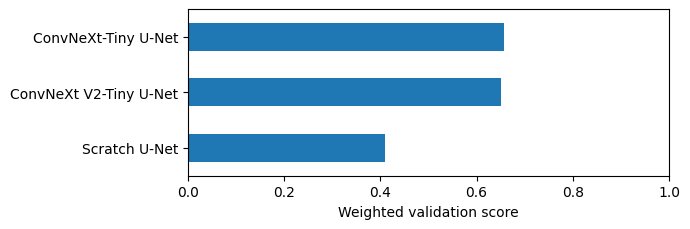

In [17]:
comparison = pd.DataFrame(model_results, columns=["Model", "Epochs", "Best epoch", "Best val score"]).set_index("Model")
comparison = comparison.sort_values("Best val score", ascending=False)
display(comparison.round(5))

comparison["Best val score"].plot.barh(xlim=(0, 1), xlabel="Weighted validation score", ylabel="", figsize=(7, 2.4)).invert_yaxis()
plt.tight_layout()
plt.show()